In [1]:
import random
import cv2
import matplotlib.pyplot as plt
from pathlib import Path

dataset_path = Path(
    r"E:\AI_ML PROJECTS\Helmet Detection\data\raw\Helmet and Number Plate Detection for Motorbike Safety.v3i.yolov8"
)

# Train images aur labels ke paths
train_images = dataset_path / "train" / "images"
train_labels = dataset_path / "train" / "labels"

print("Dataset exists:", dataset_path.exists())
print("Train images:", train_images.exists())
print("Train labels:", train_labels.exists())

Dataset exists: True
Train images: True
Train labels: True


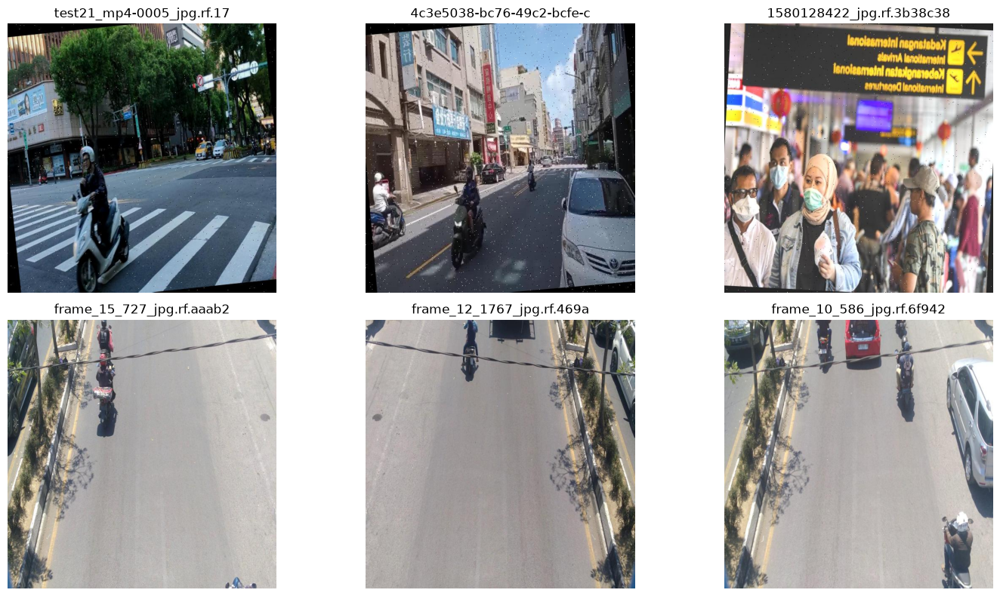

In [2]:


# collect random images from the training dataset
random.seed(42)

image_files = random.sample(list(train_images.glob("*.jpg")),6)

plt.figure(figsize=(15, 8))

for i, image_file in enumerate(image_files):

    image = cv2.imread(str(image_file))

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_file.name[:25])
    plt.axis("off")

# Grid ko properly adjust karna
plt.tight_layout()
plt.show()

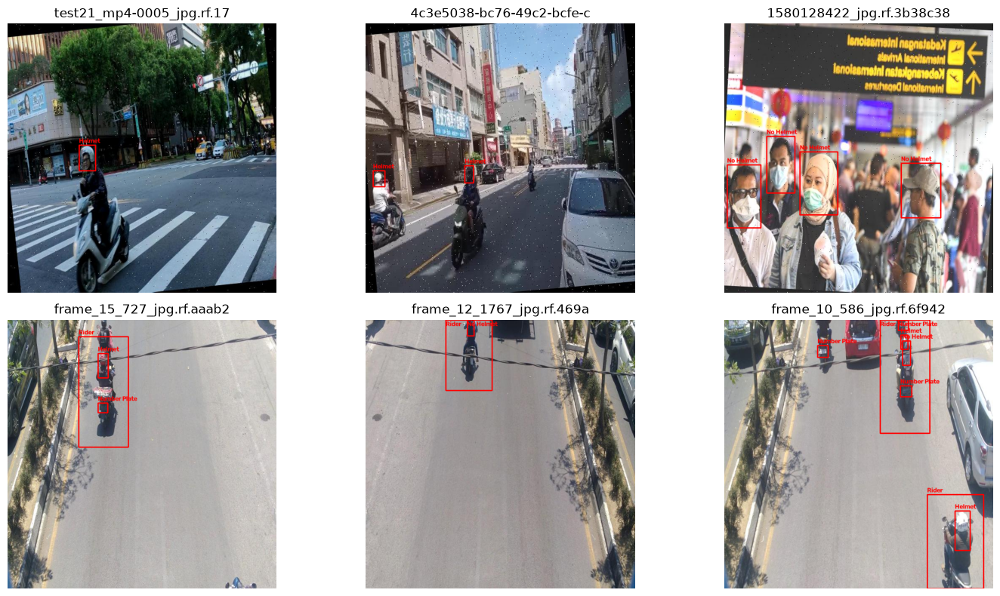

In [3]:
# Class names
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

# 6 images ko ek grid mein dikhana
plt.figure(figsize=(15, 8))

for i, image_file in enumerate(image_files):

    # Image read karna
    image = cv2.imread(str(image_file))

    # BGR → RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Image ka size
    height, width = image.shape[:2]

    # Corresponding label file
    label_file = train_labels / (image_file.stem + ".txt")

    # Label file read karna
    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            # Annotation se values nikalna
            class_id = int(values[0])
            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            # Normalized coordinates → pixel coordinates
            x_center = int(x_center * width)
            y_center = int(y_center * height)
            box_width = int(box_width * width)
            box_height = int(box_height * height)

            # Bounding box ke corners
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            # Bounding box draw karna
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            # Class name draw karna
            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    # Grid mein image show karna
    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_file.name[:25])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [4]:
# Different combinations of classes count karna

from collections import Counter

combination_count = Counter()

for label_file in train_labels.glob("*.txt"):

    classes_in_image = set()

    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            if len(values) >= 5:
                class_id = int(values[0])
                classes_in_image.add(class_id)

    # Classes ko sorted tuple mein convert karna
    combination = tuple(sorted(classes_in_image))

    combination_count[combination] += 1


# Result display karna
classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

for combination, count in combination_count.most_common():

    class_names = [classes[class_id] for class_id in combination]

    print(class_names, ":", count, "images")

['Helmet', 'No Helmet', 'Number Plate', 'Rider'] : 2785 images
['Helmet'] : 2642 images
['Helmet', 'Number Plate', 'Rider'] : 2296 images
['No Helmet'] : 1698 images
['Helmet', 'Rider'] : 770 images
['Helmet', 'No Helmet'] : 676 images
['No Helmet', 'Number Plate', 'Rider'] : 349 images
['No Helmet', 'Rider'] : 290 images
['Helmet', 'No Helmet', 'Rider'] : 144 images
['Rider'] : 84 images
['Number Plate', 'Rider'] : 74 images
['Helmet', 'Number Plate'] : 16 images
['Number Plate'] : 12 images
['No Helmet', 'Number Plate'] : 12 images
['Helmet', 'No Helmet', 'Number Plate'] : 2 images
[] : 2 images


In [5]:

no_helmet_rider = []

no_helmet_without_rider = []

for label_file in train_labels.glob("*.txt"):

    classes_in_image = set()

    with open(label_file, "r") as f:

        for line in f:
            values = line.split()

            if len(values) >= 5:
                class_id = int(values[0])
                classes_in_image.add(int(values[0]))

    # Corresponding image
    image_file = train_images / (label_file.stem + ".jpg")

    # No Helmet present
    if 1 in classes_in_image:

        # Rider bhi present hai
        if 3 in classes_in_image:
            no_helmet_rider.append(image_file)

        # Rider present nahi hai
        else:
            no_helmet_without_rider.append(image_file)


print("No Helmet + Rider:", len(no_helmet_rider))
print("No Helmet without Rider:", len(no_helmet_without_rider))

No Helmet + Rider: 3568
No Helmet without Rider: 2388


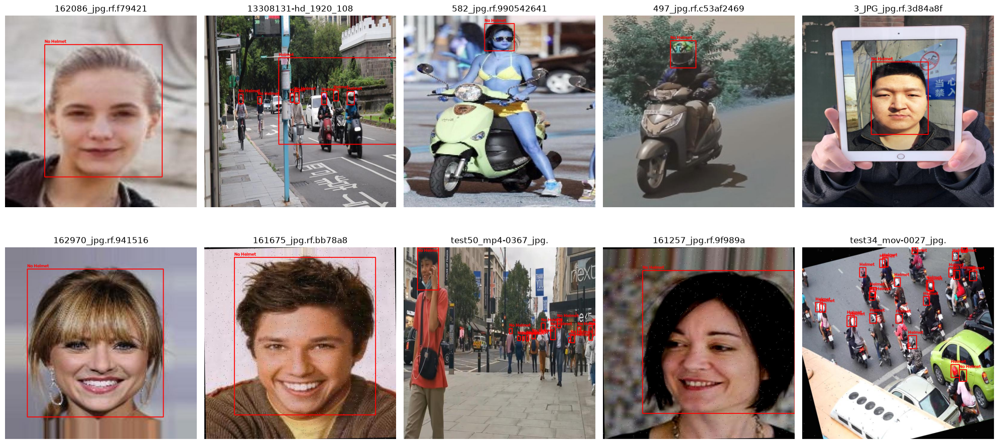

In [6]:

# Fixed random selection
random.seed(42)

# No Helmet without Rider wali images mein se 10 select karna
sample_images = random.sample(no_helmet_without_rider, 10)

# 10 images ko grid mein dikhana
plt.figure(figsize=(20, 10))

for i, image_file in enumerate(sample_images):

    # Image read karna
    image = cv2.imread(str(image_file))

    # BGR → RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Image size
    height, width = image.shape[:2]

    # Corresponding label file
    label_file = train_labels / (image_file.stem + ".txt")

    # Existing annotations read karna
    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            class_id = int(values[0])
            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            # Normalized → pixel coordinates
            x_center = int(x_center * width)
            y_center = int(y_center * height)
            box_width = int(box_width * width)
            box_height = int(box_height * height)

            # Box corners
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            # Bounding box draw
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            # Class name
            classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    # Grid mein image
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(image_file.name[:20])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
# Helmet + Rider images
helmet_rider = []

# No Helmet + Rider images
no_helmet_rider = []

# Training dataset ki har label file check karna
for label_file in train_labels.glob("*.txt"):

    classes_in_image = set()

    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            if len(values) >= 5:
                class_id = int(values[0])
                classes_in_image.add(class_id)

    # Corresponding image ka path
    image_file = train_images / (label_file.stem + ".jpg")

    # Helmet + Rider present hai
    if 0 in classes_in_image and 3 in classes_in_image:
        helmet_rider.append(image_file)

    # No Helmet + Rider present hai
    if 1 in classes_in_image and 3 in classes_in_image:
        no_helmet_rider.append(image_file)


print("Helmet + Rider images:", len(helmet_rider))
print("No Helmet + Rider images:", len(no_helmet_rider))

Helmet + Rider images: 5995
No Helmet + Rider images: 3568


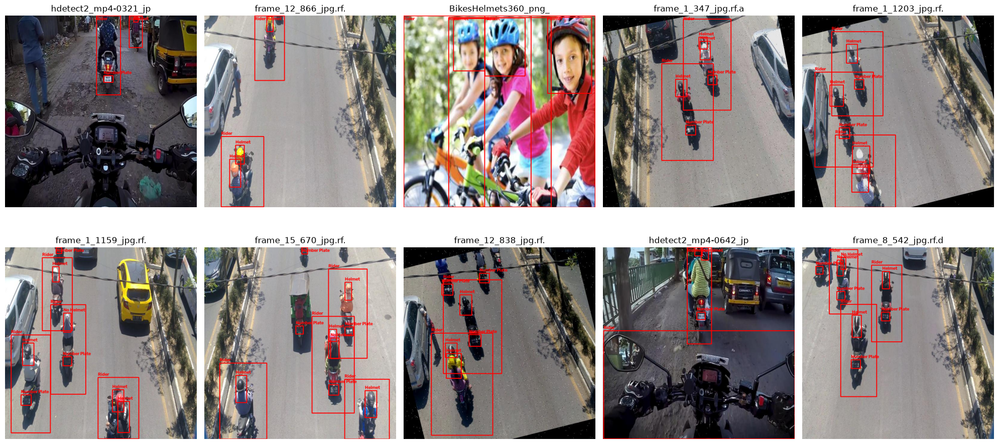

In [8]:

random.seed(42)

# Helmet + Rider images mein se 10 select karna
sample_helmet_rider = random.sample(helmet_rider, 10)

# Figure create karna
plt.figure(figsize=(20, 10))

for i, image_file in enumerate(sample_helmet_rider):

    # Image read karna
    image = cv2.imread(str(image_file))

    # BGR → RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Image dimensions
    height, width = image.shape[:2]

    # Corresponding label file
    label_file = train_labels / (image_file.stem + ".txt")

    # Labels read karna
    with open(label_file, "r") as f:

        for line in f:

            values = line.split()

            class_id = int(values[0])
            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            # Normalized coordinates ko pixels mein convert karna
            x_center = int(x_center * width)
            y_center = int(y_center * height)
            box_width = int(box_width * width)
            box_height = int(box_height * height)

            # Bounding box corners
            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)
            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            # Bounding box draw
            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            # Class name
            classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    # Grid mein image display
    plt.subplot(2, 5, i + 1)
    plt.imshow(image)
    plt.title(image_file.name[:20])
    plt.axis("off")

plt.tight_layout()
plt.show()

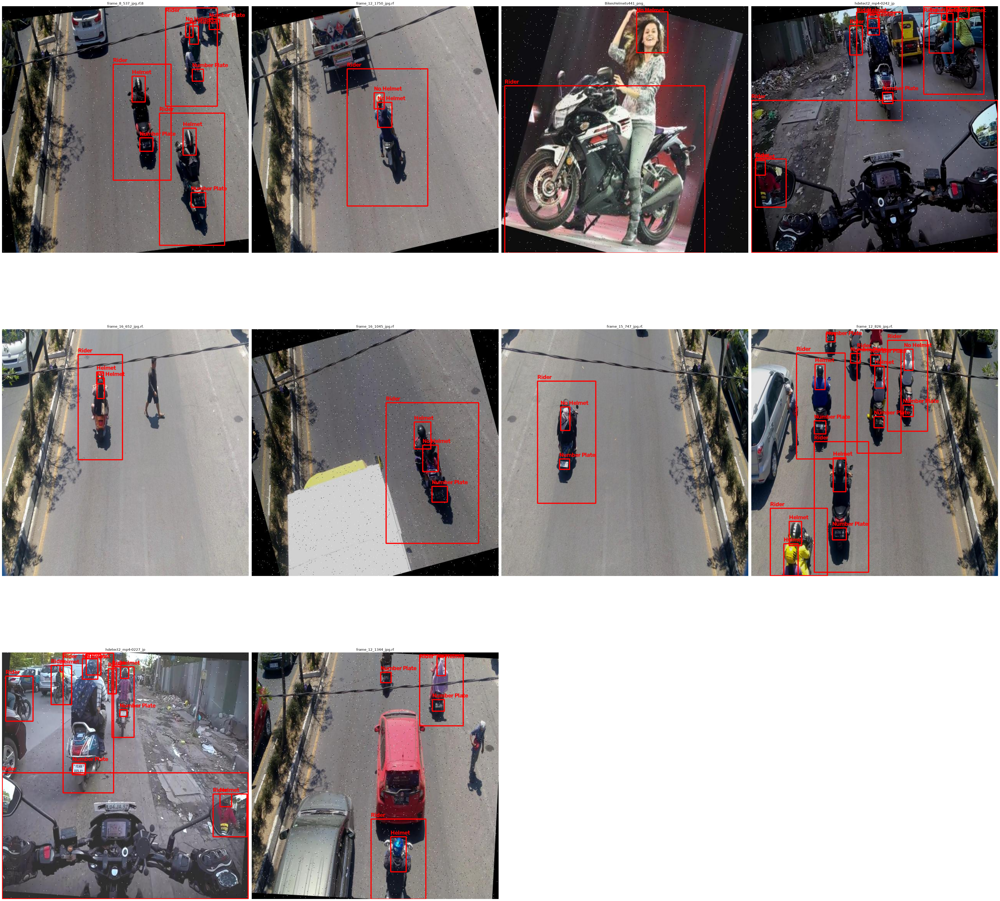

In [9]:
# no helmet + rider 10 images 
random.seed(42)

sample_no_helmet_rider = random.sample(no_helmet_rider, 10)

classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

plt.figure(figsize=(50, 50))

for i, image_file in enumerate(sample_no_helmet_rider):

    image = cv2.imread(str(image_file))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    label_file = train_labels / (image_file.stem + ".txt")

    with open(label_file, "r") as f:

        for line in f:
            values = line.split()

            class_id = int(values[0])

            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            x_center = int(x_center * width)
            y_center = int(y_center * height)

            box_width = int(box_width * width)
            box_height = int(box_height * height)

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)

            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    plt.subplot(3, 4, i + 1)
    plt.imshow(image)
    plt.title(image_file.name[:20])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
#analysis of box size helmet/no helmet
helmet_sizes = []
no_helmet_sizes = []

for label_file in train_labels.glob("*.txt"):

    with open(label_file, "r") as f:
        for line in f:
            values = line.split()

            if len(values) < 5:
                continue

            class_id = int(values[0])
            box_width = float(values[3])
            box_height = float(values[4])

            if class_id == 0:
                helmet_sizes.append((box_width, box_height))

            elif class_id == 1:
                no_helmet_sizes.append((box_width, box_height))


print("Helmet annotations:", len(helmet_sizes))
print("No Helmet annotations:", len(no_helmet_sizes))

Helmet annotations: 25717
No Helmet annotations: 11104


In [11]:
import numpy as np

helmet_areas = []
no_helmet_areas = []

for width, height in helmet_sizes:
    helmet_areas.append(width * height)

for width, height in no_helmet_sizes:
    no_helmet_areas.append(width * height)


print("Helmet average box area:",
      round(np.mean(helmet_areas) * 100, 3), "%")

print("No Helmet average box area:",
      round(np.mean(no_helmet_areas) * 100, 3), "%")

print("Helmet smallest box area:",
      round(np.min(helmet_areas) * 100, 3), "%")

print("No Helmet smallest box area:",
      round(np.min(no_helmet_areas) * 100, 3), "%")

Helmet average box area: 1.806 %
No Helmet average box area: 3.359 %
Helmet smallest box area: 0.001 %
No Helmet smallest box area: 0.004 %


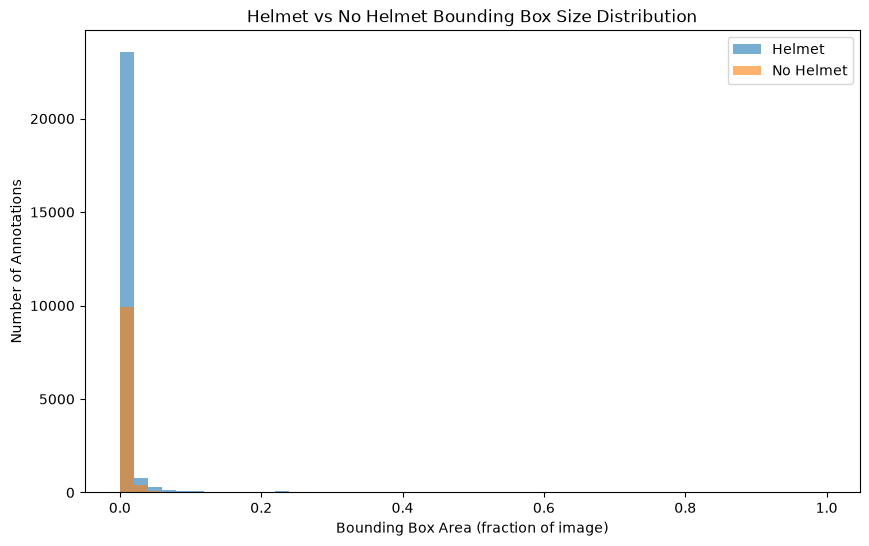

In [12]:
# box size distribution ploting
plt.figure(figsize=(10, 6))

plt.hist(
    helmet_areas,
    bins=50,
    alpha=0.6,
    label="Helmet"
)

plt.hist(
    no_helmet_areas,
    bins=50,
    alpha=0.6,
    label="No Helmet"
)

plt.xlabel("Bounding Box Area (fraction of image)")
plt.ylabel("Number of Annotations")
plt.title("Helmet vs No Helmet Bounding Box Size Distribution")
plt.legend()
plt.show()

In [13]:
# Helmet + Rider + Number Plate images
helmet_rider_plate = []

for label_file in train_labels.glob("*.txt"):

    classes_in_image = set()

    with open(label_file, "r") as f:
        for line in f:
            values = line.split()

            if len(values) >= 5:
                class_id = int(values[0])
                classes_in_image.add(class_id)

    # Exactly Helmet + Rider + Number Plate
    if classes_in_image == {0, 2, 3}:
        image_file = train_images / (label_file.stem + ".jpg")
        helmet_rider_plate.append(image_file)


print("Helmet + Rider + Number Plate images:",
      len(helmet_rider_plate))

Helmet + Rider + Number Plate images: 2296


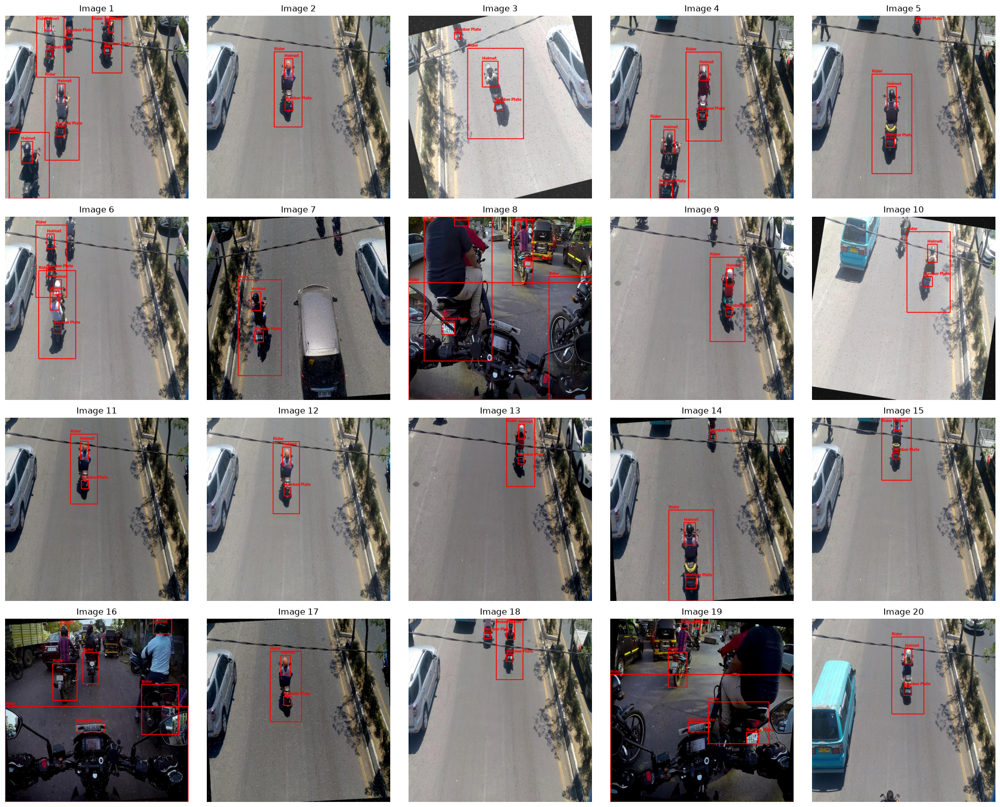

In [14]:

random.seed(42)

sample_images = random.sample(helmet_rider_plate, 20)

classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

plt.figure(figsize=(20, 16))

for i, image_file in enumerate(sample_images):

    image = cv2.imread(str(image_file))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    label_file = train_labels / (image_file.stem + ".txt")

    with open(label_file, "r") as f:
        for line in f:

            values = line.split()

            if len(values) < 5:
                continue

            class_id = int(values[0])

            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            x_center = int(x_center * width)
            y_center = int(y_center * height)

            box_width = int(box_width * width)
            box_height = int(box_height * height)

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)

            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    plt.subplot(4, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [15]:
# no helmet + rider + number plate images
no_helmet_rider_plate = []

for label_file in train_labels.glob("*.txt"):

    classes_in_image = set()

    with open(label_file, "r") as f:
        for line in f:
            values = line.split()

            if len(values) >= 5:
                class_id = int(values[0])
                classes_in_image.add(class_id)

    # Exactly No Helmet + Rider + Number Plate
    if classes_in_image == {1, 2, 3}:
        image_file = train_images / (label_file.stem + ".jpg")
        no_helmet_rider_plate.append(image_file)

print(
    "No Helmet + Rider + Number Plate images:",
    len(no_helmet_rider_plate)
)

No Helmet + Rider + Number Plate images: 349


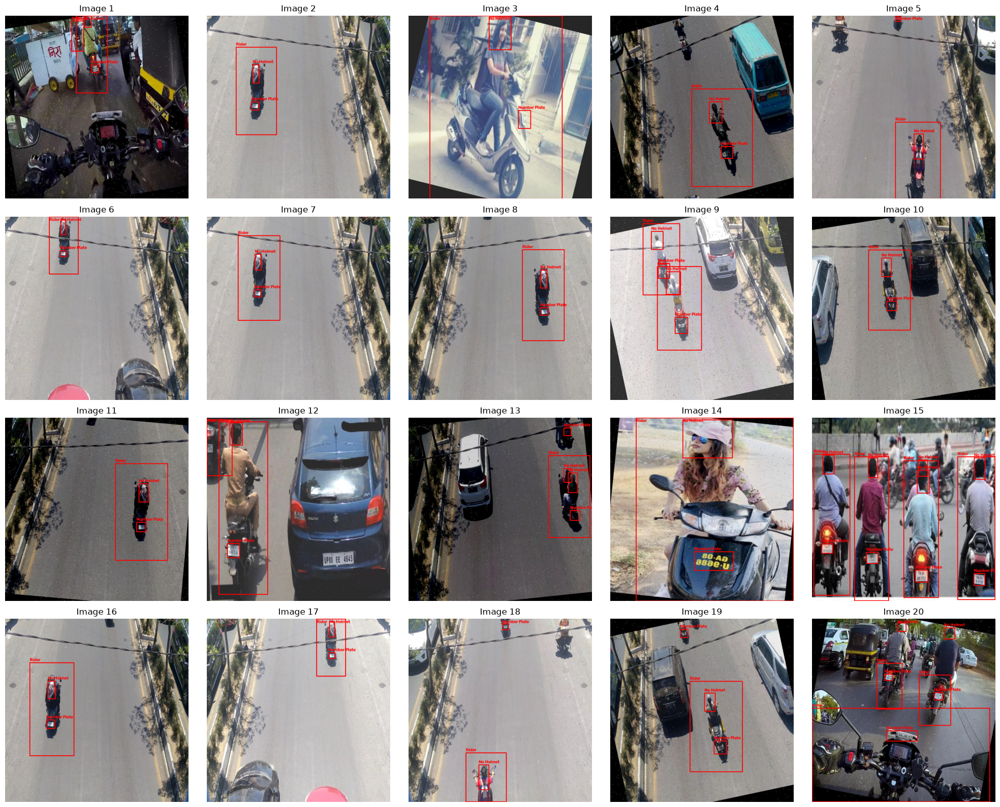

In [16]:

random.seed(42)

sample_images = random.sample(no_helmet_rider_plate, 20)

classes = ["Helmet", "No Helmet", "Number Plate", "Rider"]

plt.figure(figsize=(20, 16))

for i, image_file in enumerate(sample_images):

    image = cv2.imread(str(image_file))
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    height, width = image.shape[:2]

    label_file = train_labels / (image_file.stem + ".txt")

    with open(label_file, "r") as f:
        for line in f:

            values = line.split()

            if len(values) < 5:
                continue

            class_id = int(values[0])

            x_center = float(values[1])
            y_center = float(values[2])
            box_width = float(values[3])
            box_height = float(values[4])

            x_center = int(x_center * width)
            y_center = int(y_center * height)

            box_width = int(box_width * width)
            box_height = int(box_height * height)

            x1 = int(x_center - box_width / 2)
            y1 = int(y_center - box_height / 2)

            x2 = int(x_center + box_width / 2)
            y2 = int(y_center + box_height / 2)

            cv2.rectangle(
                image,
                (x1, y1),
                (x2, y2),
                (255, 0, 0),
                2
            )

            cv2.putText(
                image,
                classes[class_id],
                (x1, max(y1 - 5, 15)),
                cv2.FONT_HERSHEY_SIMPLEX,
                0.5,
                (255, 0, 0),
                2
            )

    plt.subplot(4, 5, i + 1)
    plt.imshow(image)
    plt.title(f"Image {i + 1}")
    plt.axis("off")

plt.tight_layout()
plt.show()